# Part 1 — RNA Velocity in Pancreatic Endocrinogenesis

This notebook reproduces the **scVelo** half of the official [CellRank 2](https://cellrank.readthedocs.io/) pancreas endocrinogenesis tutorial.

**Biological context.** During mouse pancreas development, a pool of proliferating **ductal progenitor cells** gradually turns into the hormone-producing cells of the islets of Langerhans (the *endocrine* cells: Alpha, Beta, Delta and Epsilon). This process is called **endocrinogenesis**. Because differentiation is a *dynamic* process, a single snapshot of gene expression (a normal scRNA-seq experiment) cannot tell us which direction each cell is heading. **RNA velocity** solves this by comparing newly made (unspliced) and mature (spliced) mRNA for every gene in every cell, which lets us estimate the short-term future state of each cell — essentially, an arrow pointing from "now" to "soon".

In this notebook we will:
1. Load the classic pancreas dataset (`scv.datasets.pancreas`).
2. Preprocess it (filtering, normalization, neighbor graph).
3. Fit scVelo's **dynamical model** to estimate splicing kinetics per gene.
4. Visualize the resulting velocity vector field.
5. Save the annotated data so it can be reused for the CellRank fate-mapping analysis in `02_cellrank_fates.ipynb`.

In [1]:
import scanpy as sc
import scvelo as scv
import matplotlib.pyplot as plt
from pathlib import Path

scv.settings.verbosity = 3
scv.settings.set_figure_params("scvelo", facecolor="white", dpi=100, frameon=True)

# figures/ and data/ live one level up from notebooks/
FIG_DIR = Path("../figures")
DATA_DIR = Path("../data")
FIG_DIR.mkdir(exist_ok=True)
DATA_DIR.mkdir(exist_ok=True)
scv.settings.figdir = str(FIG_DIR)

## 1. Load the dataset

`scv.datasets.pancreas()` downloads a public scRNA-seq dataset from mouse pancreas at embryonic day 15.5 (Bastidas-Ponce et al. 2019). Besides the usual gene expression matrix, it contains two extra layers per gene:

- **`spliced`** counts — mature mRNA (the "current" expression level).
- **`unspliced`** counts — newly transcribed, not-yet-processed mRNA (a proxy for very recent transcriptional activity).

Comparing these two layers per gene is what makes RNA velocity estimation possible.

In [2]:
adata = scv.datasets.pancreas()
adata

  0%|          | 0.00/50.0M [00:00<?, ?B/s]

AnnData object with n_obs × n_vars = 3696 × 27998
    obs: 'clusters_coarse', 'clusters', 'S_score', 'G2M_score'
    var: 'highly_variable_genes'
    uns: 'clusters_coarse_colors', 'clusters_colors', 'day_colors', 'neighbors', 'pca'
    obsm: 'X_pca', 'X_umap'
    layers: 'spliced', 'unspliced'
    obsp: 'distances', 'connectivities'

The `clusters` annotation already tells us the cell types present: **Ductal** progenitors, two stages of **Ngn3+ endocrine progenitors** (`Ngn3 low EP`, `Ngn3 high EP`), **Pre-endocrine** cells, and the four mature hormone-producing types — **Alpha**, **Beta**, **Delta** and **Epsilon** cells. Biologically, this is the expected differentiation path:

`Ductal → Ngn3 low EP → Ngn3 high EP → Pre-endocrine → {Alpha, Beta, Delta, Epsilon}`

Let's check how much unspliced vs. spliced signal we have, since velocity estimation needs enough of both.

saving figure to file ..\figures/scvelo_proportions_01_spliced_unspliced_proportions.png


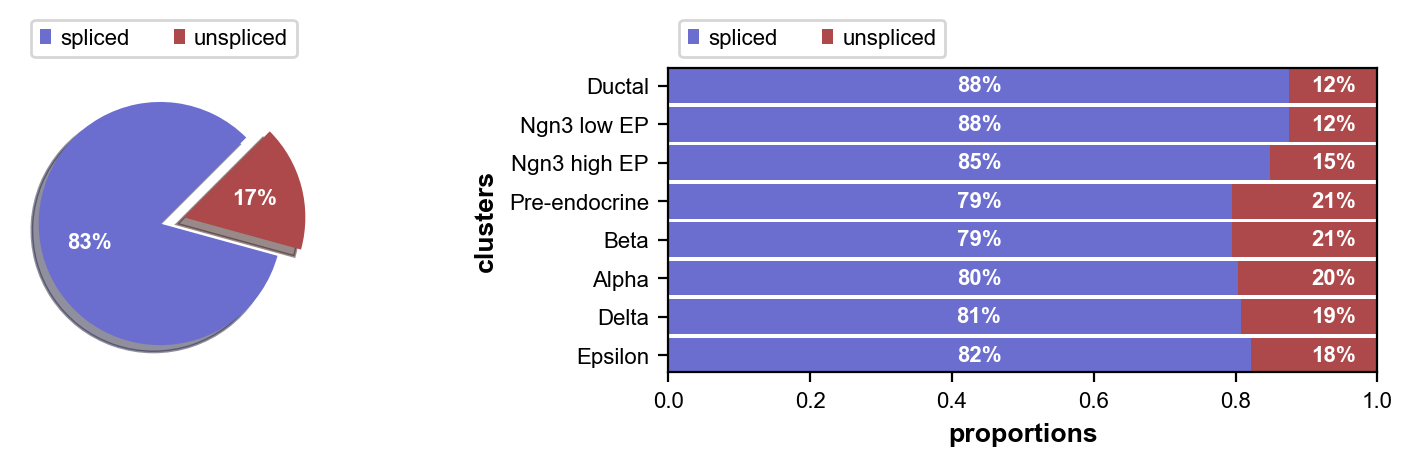

In [3]:
scv.pl.proportions(adata, groupby="clusters", save="01_spliced_unspliced_proportions.png")

## 2. Preprocess the data

Before estimating velocity we need to clean up and standardize the data, same as any scRNA-seq analysis:

- **Filter genes** that have too few spliced/unspliced counts — these are too noisy to fit reliably.
- **Normalize** each cell's counts (correct for sequencing-depth differences between cells) and **log-transform** so that highly expressed genes don't dominate.
- **Select highly variable genes (HVGs)** — the ~2,000 genes that vary most across cells. These are the genes that actually carry information about cell identity and differentiation; using them (instead of all ~28,000 genes) makes downstream steps faster and less noisy.
- **Build a PCA + k-nearest-neighbor (kNN) graph** of the cells — a map of which cells are transcriptionally similar to which others.
- **Compute moments** (`scv.pp.moments`) — for every gene, average its spliced/unspliced counts over each cell's nearest neighbors. Single-cell data is noisy and sparse (many zero counts), so this neighbor-averaging step is what makes it possible to fit smooth splicing kinetics per gene in the next section.

In [4]:
scv.pp.filter_genes(adata, min_shared_counts=20)
scv.pp.normalize_per_cell(adata)

sc.pp.log1p(adata)
sc.pp.highly_variable_genes(adata, n_top_genes=2000)

sc.tl.pca(adata)
sc.pp.neighbors(adata, n_pcs=30, n_neighbors=30, random_state=0)
scv.pp.moments(adata, n_pcs=None, n_neighbors=None)

Filtered out 20801 genes that are detected 20 counts (shared).


Normalized count data: X, spliced, unspliced.


computing moments based on connectivities


    finished (0:00:02) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)


## 3. Fit the dynamical model

For each gene, scVelo's **dynamical model** fits a small kinetic (ODE-based) model of transcription:

> DNA → (transcription) → unspliced mRNA → (splicing) → spliced mRNA → (degradation) → gone

Each gene gets its own transcription rate, splicing rate and degradation rate, plus a per-cell estimate of *where* that cell sits along the gene's induction/repression cycle (i.e. is this gene currently being turned **on** or turned **off** in this cell?). This is more accurate than the simpler "steady-state" model because real genes are rarely at a single equilibrium — during differentiation, genes are constantly being switched on and off.

`scv.tl.recover_dynamics` fits these kinetics, and `scv.tl.velocity(..., mode="dynamical")` then uses the fitted model to compute, for every cell and every gene, the predicted rate of change of spliced mRNA — i.e. the **velocity vector**. Positive velocity means a gene's spliced expression is expected to increase soon (the gene is being induced); negative means it's expected to decrease (the gene is being shut off).

This step is the most computationally expensive one in the whole workflow (it fits an ODE per gene) — it can take several minutes.

In [5]:
import os

n_jobs = max(1, (os.cpu_count() or 1) - 1)
scv.tl.recover_dynamics(adata, n_jobs=n_jobs)
scv.tl.velocity(adata, mode="dynamical")
scv.tl.velocity_graph(adata, n_jobs=n_jobs)

recovering dynamics (using 11/12 cores)


  0%|          | 0/1295 [00:00<?, ?gene/s]

    finished (0:08:48) --> added 
    'fit_pars', fitted parameters for splicing dynamics (adata.var)


computing velocities


    finished (0:00:10) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)


computing velocity graph (using 11/12 cores)


  0%|          | 0/3696 [00:00<?, ?cells/s]

    finished (0:00:09) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)


## 4. Visualize the velocity vector field

`scv.tl.velocity_graph` compares each cell's high-dimensional velocity vector to the displacement toward its neighbors, producing a cell-to-cell transition likelihood graph (this is also the computation that CellRank's `VelocityKernel` redoes in notebook 2 to build a formal Markov chain). We can project this graph onto the UMAP embedding as a **streamline plot**: arrows/streamlines show the direction each region of the differentiation landscape is flowing towards.

Biologically, we expect to see flow starting at the Ductal/Ngn3-low progenitors and streaming outward into the four mature endocrine cell types.

computing velocity embedding


    finished (0:00:01) --> added
    'velocity_umap', embedded velocity vectors (adata.obsm)


saving figure to file ..\figures/scvelo_02_velocity_embedding_stream.png


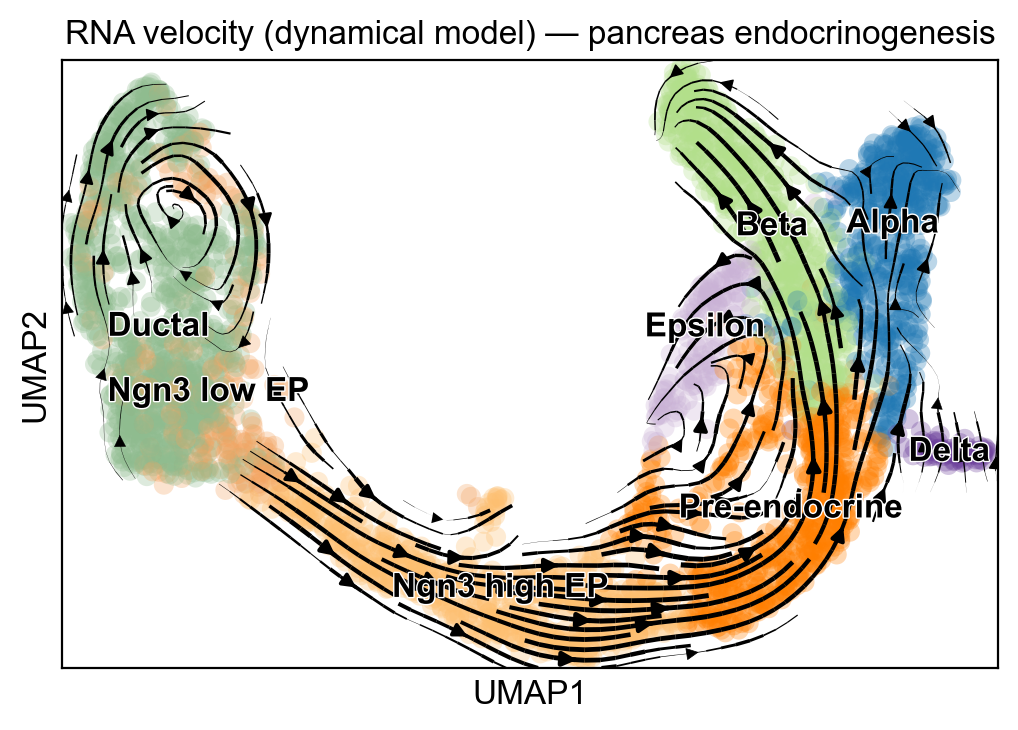

In [6]:
scv.pl.velocity_embedding_stream(
    adata,
    basis="umap",
    color="clusters",
    title="RNA velocity (dynamical model) — pancreas endocrinogenesis",
    save="02_velocity_embedding_stream.png",
)

## 5. Save the result

We save the `AnnData` object — now containing the fitted dynamical model and per-cell/per-gene velocities — to disk. This is what `02_cellrank_fates.ipynb` will load to build the CellRank `VelocityKernel` and map cell fates, without needing to redo the (slow) velocity fitting step.

In [7]:
adata.write(DATA_DIR / "pancreas_velocity.h5ad")